# Nucleus segmentation for Visium — Colorectal Cancer H&E (Cellpose-SAM with GPU)

**Goal.** Turn the whole-slide H&E of the 10x *Human Colorectal Cancer (11 mm, FFPE)* Visium sample
into a table of **nucleus centroids** (`nuclei.csv`, columns `x,y`), which the R DenMark pipeline then
counts per 55 µm spot to build the cell-**density** field `Y`.

In [ ]:
# === CONFIGURE ME ===
import os
DATA_DIR = '../../data'      # holds the 10x Visium CRC download in Revision-R1/spot-Visium/ (see README.md)
OUTPUT_DIR = '../../output'  # nuclei.csv, spot_celltype.csv and the figures go to Revision-R1/spot-Visium/ below it
REPO_ROOT = '../..'          # root of the DenMark checkout (defaults assume Jupyter starts in this folder)
os.makedirs(f"{OUTPUT_DIR}/Revision-R1/spot-Visium", exist_ok=True)
# ====================

In [1]:
# pip install "cellpose>=4" tifffile imagecodecs pandas numpy scipy matplotlib
import warnings
warnings.filterwarnings("ignore")   # silence Cellpose/torch sparse-tensor UserWarnings

## Step 1 — Imports and parameters

In [3]:
import os, json
import numpy as np
import pandas as pd
import tifffile

# ---- switch ----
SEGMENT_HIRES = False

# ---- paths (EDIT to your machine) ----
BASE          = f"{DATA_DIR}/Revision-R1/spot-Visium"
SPATIAL_DIR   = os.path.join(BASE, "CytAssist_11mm_FFPE_Human_Colorectal_Cancer_spatial", "spatial")
IMAGE_FULLRES = os.path.join(BASE, "CytAssist_11mm_FFPE_Human_Colorectal_Cancer_tissue_image.tif")
OUT_CSV       = os.path.join(f"{OUTPUT_DIR}/Revision-R1/spot-Visium", "nuclei.csv")

# ---- segmentation params ----
DS    = 1          # keep 1 for the block loop (full-res -> nuclei ~30 px = Cellpose-SAM native)
BLOCK = 2048       # block size (px)
PAD   = 96         # block overlap (px)
BATCH = 4          # per-block batch size; lower to 2 if CUDA out-of-memory

# ---- scalefactors: convert segmented-image px -> FULL-RES px ----
with open(os.path.join(SPATIAL_DIR, "scalefactors_json.json")) as f:
    SF = json.load(f)

if SEGMENT_HIRES:
    IMAGE   = os.path.join(SPATIAL_DIR, "tissue_hires_image.png")
    PX2FULL = 1.0 / SF["tissue_hires_scalef"]
else:
    IMAGE   = IMAGE_FULLRES
    PX2FULL = 1.0

umpx_full = 55.0 / SF["spot_diameter_fullres"]
umpx_work = umpx_full * PX2FULL * DS
assert os.path.exists(IMAGE), f"image not found: {IMAGE}"
print("segmenting:", IMAGE)
print(f"px->fullres factor : {PX2FULL:.4f}")
print(f"working resolution : ~{umpx_work:.3f} um/pixel  (full-res ~0.25 is what Cellpose-SAM wants)")

segmenting: <DATA_DIR>/Revision-R1/spot-Visium\CytAssist_11mm_FFPE_Human_Colorectal_Cancer_tissue_image.tif
px->fullres factor : 1.0000
working resolution : ~0.251 um/pixel  (full-res ~0.25 is what Cellpose-SAM wants)


## Step 2 — Load the H&E (largest pyramid level) and clean to RGB uint8

CytAssist `tissue_image.tif` is pyramidal; `_read_biggest_tif` grabs the level with the most pixels
(the full-res base) so we don't accidentally segment a small overview. Then standardise: squeeze,
channel order, force RGB, drop alpha, 8-bit. We do **not** normalise the whole slide to float here —
Cellpose normalises each block internally.

In [5]:
import tifffile

def _read_biggest_tif(path):
    with tifffile.TiffFile(path) as tf:
        best, best_px = None, -1
        for s in tf.series:
            for lvl in s.levels:
                if lvl.size > best_px:              # size = total pixel count
                    best, best_px = lvl, lvl.size
        return best.asarray()

def load_image(path, downscale):
    print(f"reading {path} ...")
    if path.lower().endswith((".tif", ".tiff")):
        img = _read_biggest_tif(path)
    else:
        import matplotlib.pyplot as plt
        img = plt.imread(path)

    img = np.squeeze(np.asarray(img))
    if img.ndim == 3 and img.shape[0] in (3, 4) and img.shape[-1] not in (3, 4):
        img = np.moveaxis(img, 0, -1)
    if img.ndim == 2:
        img = np.stack([img] * 3, axis=-1)
    assert img.ndim == 3, f"unexpected shape {img.shape}"
    img = img[:, :, :3]

    if img.dtype != np.uint8:
        if img.max() <= 1.0:
            img = (img * 255).astype(np.uint8)
        else:
            lo, hi = np.percentile(img, [0.1, 99.9])
            img = np.clip((img.astype(np.float32) - lo) / max(hi - lo, 1e-6), 0, 1)
            img = (img * 255).astype(np.uint8)

    print("  full-resolution shape:", img.shape, img.dtype)
    if downscale > 1:
        img = img[::downscale, ::downscale, :]
        print(f"  downscaled {downscale}x -> {img.shape}")
    return img

img = load_image(IMAGE, DS)
print("working array:", img.shape, "=", round(img.shape[0]*img.shape[1]/1e6), "MP")

reading <DATA_DIR>/Revision-R1/spot-Visium\CytAssist_11mm_FFPE_Human_Colorectal_Cancer_tissue_image.tif ...
  full-resolution shape: (44403, 51996, 3) uint8
working array: (44403, 51996, 3) = 2309 MP


## Step 3 — Load Cellpose-SAM on the GPU

Cellpose 4.x uses one generalist model — no `model_type` / `channels` (those were 3.x). Confirm CUDA.

In [7]:
import torch
from cellpose import models
print("CUDA available:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
model = models.CellposeModel(gpu=True)
print("model loaded; using GPU:", getattr(model, "gpu", "n/a"))

CUDA available: True | NVIDIA GeForce RTX 4060 Laptop GPU
model loaded; using GPU: True


## Step 4 — Segment in blocks (the memory-safe loop)

We slide a `BLOCK`×`BLOCK` window (with `PAD` overlap) across the slide and run Cellpose on each block
with **`diameter=0`** (native size, no upscaling). Centroids are shifted back to whole-slide coordinates
and filtered to `< BLOCK` so the padded margin isn't double-counted. Near-white blocks (background) are
skipped. Expect `no seeds found ... no masks found` on empty blocks and `row k/N done` per row — both
normal. A few minutes on your GPU.

In [ ]:
import numpy as np, torch
from scipy import ndimage as ndi

H, W = img.shape[:2]
all_x, all_y = [], []
ny = len(range(0, H, BLOCK))

for bi, y0 in enumerate(range(0, H, BLOCK)):
    for x0 in range(0, W, BLOCK):
        y1, x1 = min(y0 + BLOCK + PAD, H), min(x0 + BLOCK + PAD, W)
        tile = img[y0:y1, x0:x1, :]
        if tile.mean() > 245:                          # skip near-white background
            continue
        m = model.eval(tile, diameter=0, batch_size=BATCH)[0]   # diameter=0 -> no rescale
        ids = np.unique(m); ids = ids[ids != 0]
        if ids.size == 0:
            continue
        cy, cx = np.array(ndi.center_of_mass(np.ones_like(m, np.uint8), m, ids)).T
        keep = (cy < BLOCK) & (cx < BLOCK)             # drop pad margin -> no double counts
        all_y.append(cy[keep] + y0); all_x.append(cx[keep] + x0)
        torch.cuda.empty_cache()
    print(f"row {bi+1}/{ny} done")

row_seg = np.concatenate(all_y); col_seg = np.concatenate(all_x)
print(f"{len(row_seg):,} nuclei detected")

no seeds found in get_masks_torch - no masks found.


row 1/22 done
row 2/22 done


no seeds found in get_masks_torch - no masks found.


row 3/22 done


no seeds found in get_masks_torch - no masks found.


row 4/22 done
row 5/22 done
row 6/22 done
row 7/22 done
row 8/22 done
row 9/22 done
row 10/22 done
row 11/22 done
row 12/22 done
row 13/22 done
row 14/22 done
row 15/22 done
row 16/22 done


no seeds found in get_masks_torch - no masks found.


row 17/22 done
row 18/22 done
row 19/22 done
row 20/22 done
row 21/22 done


no seeds found in get_masks_torch - no masks found.
no seeds found in get_masks_torch - no masks found.


row 22/22 done
547,877 nuclei detected


In [ ]:
import numpy as np, os

# full-res coords (DS=1 so these equal row/col_seg; keeps it correct if DS ever changes)
xs = col_seg * DS * PX2FULL
ys = row_seg * DS * PX2FULL

# save both the raw segmentation coords and the full-res coords
np.savez_compressed(
    os.path.join(f"{OUTPUT_DIR}/Revision-R1/spot-Visium", "nuclei_seg.npz"),
    row_seg=row_seg, col_seg=col_seg, xs=xs, ys=ys,
)
print("saved", len(xs), "nuclei ->", os.path.join(f"{OUTPUT_DIR}/Revision-R1/spot-Visium", "nuclei_seg.npz"))

saved 547877 nuclei -> <OUTPUT_DIR>/Revision-R1/spot-Visium\nuclei_seg.npz


In [11]:
# load the results: 
#import numpy as np, os
#d = np.load(os.path.join(f"{OUTPUT_DIR}/Revision-R1/spot-Visium", "nuclei_seg.npz"))
#row_seg, col_seg, xs, ys = d["row_seg"], d["col_seg"], d["xs"], d["ys"]
#print(f"loaded {len(xs):,} nuclei")

loaded 547,877 nuclei


## Step 5 — Rescale to FULL resolution

`row_seg/col_seg` are in the working-image frame (for QC). `xs, ys` are full-res: multiply by `DS`
(undo any downscale) and `PX2FULL` (undo hires→full, = 1 for the TIF). With `DS=1` these equal the
working coords — but keeping the formula means the notebook stays correct if you ever change `DS`.

In [ ]:
xs = col_seg * DS * PX2FULL
ys = row_seg * DS * PX2FULL
print(f"{len(xs):,} nuclei")
print("full-res x:", int(xs.min()), "-", int(xs.max()))
print("full-res y:", int(ys.min()), "-", int(ys.max()))

547,877 nuclei
full-res x: 175 - 50112
full-res y: 158 - 44373


## Step 6 — QC overlay (segmentation quality)

Centroids over the H&E thumbnail. Dots should sit on nuclei — dense in tumour glands, sparse in
stroma/whitespace. Subsampled `[::10]` so plotting half a million points stays fast. This checks
*segmentation*; the *spot-alignment* check happens later in R (`QC_nuclei_vs_spots_CRC.png`).

In [ ]:
import pandas as pd, os
from scipy.spatial import cKDTree

pos = pd.read_csv(os.path.join(SPATIAL_DIR, "tissue_positions.csv"))
pos = pos[pos.in_tissue == 1]
xy  = pos[["pxl_col_in_fullres", "pxl_row_in_fullres"]].values
d, _ = cKDTree(xy).query(xy, k=2)
pitch_px = float(np.median(d[:, 1]))          # ~363 px == 100 um center-to-center
print("pitch_px:", round(pitch_px, 1), "-> um/px:", round(100/pitch_px, 4))

pitch_px: 363.1 -> um/px: 0.2754


capture area: 11.4 x 11.2 mm (expect ~11 x 11)


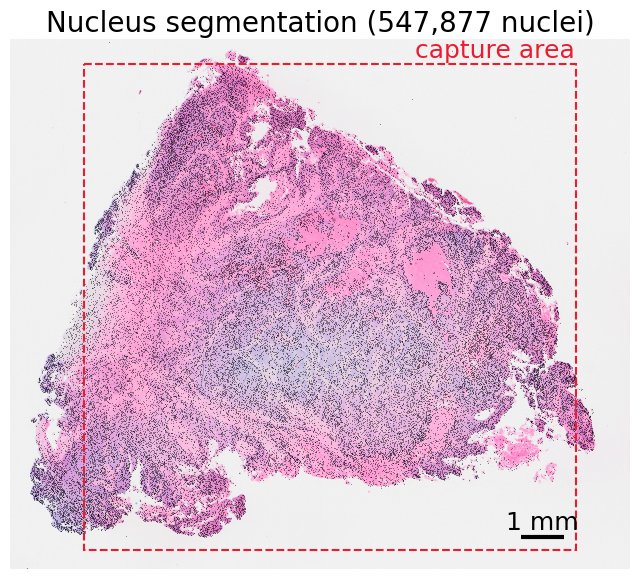

In [ ]:
# add the capture area box 
import numpy as np, pandas as pd, os
from matplotlib.patches import Rectangle
from scipy.spatial import cKDTree

# ---- physical scale from spot pitch ----
pos_all = pd.read_csv(os.path.join(SPATIAL_DIR, "tissue_positions.csv"))
xy_full = pos_all[["pxl_col_in_fullres", "pxl_row_in_fullres"]].values     # ALL spots (in + out of tissue)
d, _ = cKDTree(xy_full).query(xy_full, k=2)
pitch_px  = float(np.median(d[:, 1]))
UM_PER_PX = 100.0 / pitch_px
BAR_UM    = 1000

um_per_plotpx = UM_PER_PX * step
bar_plotpx    = BAR_UM / um_per_plotpx

# ---- capture-area box: extent of ALL spot centres, in PLOTTED coords ----
# add half a pitch on each side so the box covers spot edges, not just centres
half = 0.5 * pitch_px
cap_x0 = (xy_full[:, 0].min() - half) / step
cap_y0 = (xy_full[:, 1].min() - half) / step
cap_w  = (xy_full[:, 0].max() - xy_full[:, 0].min() + 2*half) / step
cap_h  = (xy_full[:, 1].max() - xy_full[:, 1].min() + 2*half) / step
print(f"capture area: {cap_w*um_per_plotpx/1000:.1f} x {cap_h*um_per_plotpx/1000:.1f} mm (expect ~11 x 11)")

idx = np.arange(0, len(xs), 10)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(img[::step, ::step])
ax.scatter(col_seg[idx] / step, row_seg[idx] / step, s=0.3, c="black", alpha=0.5, linewidths=0)

# ---- capture-area boundary box ----
ax.add_patch(Rectangle((cap_x0, cap_y0), cap_w, cap_h,
                       fill=False, edgecolor="#ED1B2F", lw=1.5, linestyle="--"))
ax.text(cap_x0 + cap_w - 4, cap_y0 - 6, "capture area",
        color="#ED1B2F", fontsize=18, va="bottom", ha='right' )

ax.axis("off"); ax.set_title(f"{len(xs):,} nuclei (Cellpose-SAM)")

# ---- scale bar: fully inside the box, bottom-right corner ----
margin = 0.02 * W_plot
x1 = cap_x0 + cap_w - margin          # bar's RIGHT end, just inside the box's right edge
x0 = x1 - bar_plotpx                   # bar's left end
y0 = cap_y0 + cap_h - margin           # just above the box's bottom edge

ax.plot([x0, x1], [y0, y0], color="black", lw=3, solid_capstyle="butt")
ax.text((x0 + x1) / 2, y0 - 8, f"{BAR_UM/1000:g} mm",
        ha="center", va="bottom", color="black", fontsize=18)
ax.set_title(f"Nucleus segmentation ({len(xs):,} nuclei)", fontsize=20)

plt.savefig(os.path.join(f"{OUTPUT_DIR}/Revision-R1/spot-Visium", "nuclei_seg_cellpose.png"), dpi=200, bbox_inches="tight")
plt.show()

## Step 7 — Visualize cell locations only (no image behind)

Two views of just the segmented cells. **Left idea (scatter):** every nucleus as a dot — shows the raw
spatial pattern / tissue architecture. **Density (hist2d):** cells per bin — a preview of the `Y`
density field DenMark will model (bright = dense tumour glands, dark = stroma/whitespace). We
`invert_yaxis()` because image rows increase downward.

## Step 8 — Save `nuclei.csv` for R

Two columns, `x,y`, full-resolution pixels. Because the rescale is baked in, set `NUC_SCALE <- 1` in R.

In [ ]:
pd.DataFrame({"x": xs, "y": ys}).to_csv(OUT_CSV, index=False)
print("wrote", OUT_CSV, "with", len(xs), "nuclei")

print("\nIn DenMark_realVisium_CRC_libsize.R set:")
print(f'  NUC_FILE  <- "{os.path.abspath(OUT_CSV)}"')
print('  NUC_X <- "x"; NUC_Y <- "y"')
print("  NUC_SCALE <- 1")

wrote <OUTPUT_DIR>/Revision-R1/spot-Visium\nuclei.csv with 547877 nuclei

In DenMark_realVisium_CRC_libsize.R set:
  NUC_FILE  <- "<OUTPUT_DIR>\Revision-R1\spot-Visium\nuclei.csv"
  NUC_X <- "x"; NUC_Y <- "y"
  NUC_SCALE <- 1


In [ ]:
# check the spot size 
import pandas as pd, numpy as np
from scipy.spatial import cKDTree
pos = pd.read_csv(f"{SPATIAL_DIR}/tissue_positions.csv")
pos = pos[pos.in_tissue == 1]
xy = pos[["pxl_col_in_fullres","pxl_row_in_fullres"]].values
d, _ = cKDTree(xy).query(xy, k=2)          # nearest neighbour distance, px
nn_px = np.median(d[:,1])
umpx  = 55.0 / SF["spot_diameter_fullres"]
print(f"nearest-spot spacing: {nn_px:.1f} px = {nn_px*umpx:.1f} um  (expect ~100)")

nearest-spot spacing: 363.1 px = 91.1 um  (expect ~100)


In [ ]:
umpx_from_spacing = 100.0 / nn_px          # 100 um expected / 363.1 px
print(f"umpx from diameter: {55/SF['spot_diameter_fullres']:.4f}")
print(f"umpx from spacing : {umpx_from_spacing:.4f}")   # 0.2754

umpx from diameter: 0.2510
umpx from spacing : 0.2754


In [ ]:
# annotate the 'tumor spots'

  tumor: missing ['KRT18']
        tumor_score  immune_score  stroma_score
leiden                                         
0              0.80         -0.09          0.89
1              0.88         -0.15          0.11
2              0.93         -0.14         -0.51
3              0.89         -0.06         -0.39
4              0.76         -0.12         -0.10
5              0.45          0.08          1.82
6             -0.18          0.03          1.99
7              0.01          0.06          2.83
8             -0.01          0.07          2.83
9              0.90         -0.03          0.31
10             0.70         -0.03         -0.20
11             0.60          0.33          0.25
12             0.02          0.09          1.52
13             0.51          0.13          1.51
14             0.84         -0.18         -0.33
15             0.36          0.05          2.34
16             0.69         -0.05          1.53
17             1.24          0.03          0.53
18           

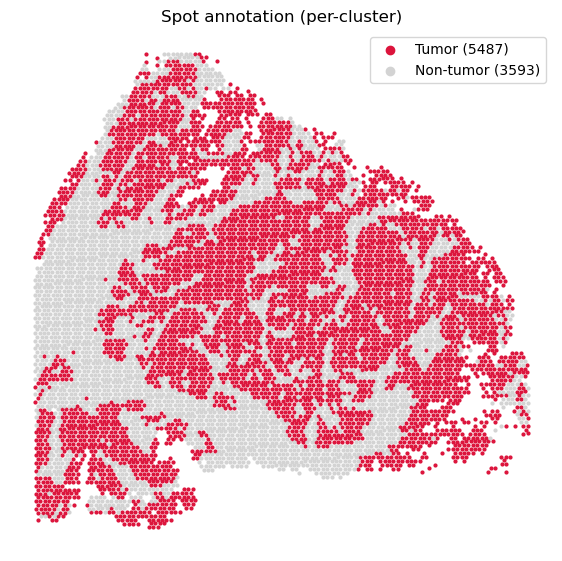

wrote <OUTPUT_DIR>/Revision-R1/spot-Visium\spot_celltype.csv


In [ ]:
import scanpy as sc, numpy as np, pandas as pd, os, matplotlib.pyplot as plt

H5 = os.path.join(BASE, "CytAssist_11mm_FFPE_Human_Colorectal_Cancer_filtered_feature_bc_matrix.h5")
adata = sc.read_10x_h5(H5)
adata.var_names_make_unique()

# ---- normalize -> cluster (same idea as the web_summary clustering) ----
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata                                     # keep full normalized matrix for scoring
sc.pp.highly_variable_genes(adata, n_top_genes=2000)
adata = adata[:, adata.var.highly_variable].copy()
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, n_comps=30)
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30)
sc.tl.leiden(adata, resolution=1.0, flavor="igraph", n_iterations=2, directed=False)

# ---- score each cluster against marker programs (on the normalized raw matrix) ----
markers = {
    "tumor":  ["EPCAM","KRT8","KRT18","KRT20","CDX2","CEACAM5"],
    "immune": ["PTPRC","CD3D","CD8A","CD68","MS4A1"],
    "stroma": ["COL1A1","COL1A2","DCN","PDGFRB","LUM"],
}
raw = adata.raw.to_adata()
for name, genes in markers.items():
    g = [x for x in genes if x in raw.var_names]
    missing = set(genes) - set(g)
    if missing:
        print(f"  {name}: missing {sorted(missing)}")
    sc.tl.score_genes(raw, g, score_name=name + "_score")
    adata.obs[name + "_score"] = raw.obs[name + "_score"].values

# ---- OPTION B: label each CLUSTER as tumor vs nontumor, then paint its spots ----
score_cols = [m + "_score" for m in markers]
cluster_mean = adata.obs.groupby("leiden", observed=True)[score_cols].mean()

# a cluster is "tumor" if its mean tumor score exceeds its mean stroma score
tumor_clusters = cluster_mean.index[cluster_mean["tumor_score"] > cluster_mean["stroma_score"]]
adata.obs["celltype"] = np.where(
    adata.obs["leiden"].isin(tumor_clusters), "Tumor", "Non-tumor"
)

print(cluster_mean.round(2))
print("tumor clusters:", list(tumor_clusters))
print(adata.obs["celltype"].value_counts())

# ---- spatial QC map: do tumor spots sit on the tumor tissue? ----
posq = pd.read_csv(os.path.join(SPATIAL_DIR, "tissue_positions.csv")).set_index("barcode")
common = adata.obs_names.intersection(posq.index)
adata = adata[common].copy()
adata.obs["row"] = posq.loc[common, "pxl_row_in_fullres"].values
adata.obs["col"] = posq.loc[common, "pxl_col_in_fullres"].values

colmap = {"Tumor": "crimson", "Non-tumor": "lightgrey"}
plt.figure(figsize=(7, 7))
for t, c in colmap.items():
    s = adata.obs[adata.obs.celltype == t]
    plt.scatter(s.col, s.row, s=4, c=c, label=f"{t} ({len(s)})")
plt.gca().invert_yaxis(); plt.gca().set_aspect("equal")
plt.legend(markerscale=3); plt.axis("off"); plt.title("Spot annotation (per-cluster)")
plt.savefig(os.path.join(f"{OUTPUT_DIR}/Revision-R1/spot-Visium", "spot_celltype_map.png"), dpi=200, bbox_inches="tight")
plt.show()

# ---- export for R ----
out = os.path.join(f"{OUTPUT_DIR}/Revision-R1/spot-Visium", "spot_celltype.csv")
pd.DataFrame({"barcode": adata.obs_names, "celltype": adata.obs["celltype"].values}) \
  .to_csv(out, index=False)
print("wrote", out)

## What happens next (in R)

1. Load spot × gene matrix + `tissue_positions.csv`; px→µm via `spot_diameter_fullres` (55 µm spot);
   per-spot **total UMI** = sequencing depth.
2. Assign each nucleus to its nearest spot (`RANN::nn2`), keep within the 27.5 µm disc → **`Y` = cells/spot**.
3. **Aperture-7 (7-spot) pooling** → super-cells.
4. Fit **DenMark** with `log(area)` on density and **`log(UMI)`** on expression → **`Astar[2,1]`** per gene.

zoom window: x 39952-40860, y 27240-28148 px  (250 um square)
590 nuclei in the zoom window


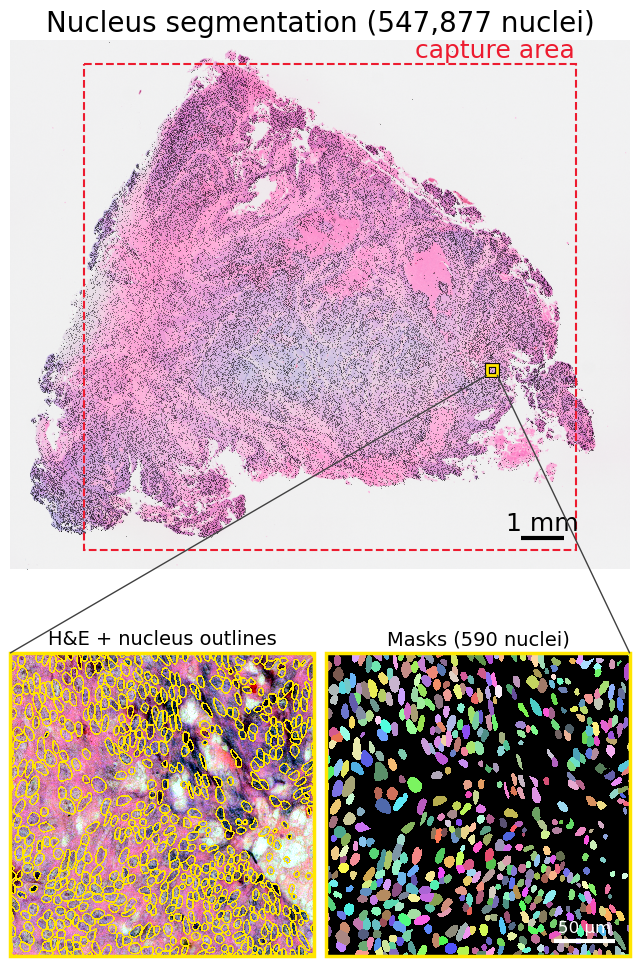

In [17]:
# =====================================================================
# Panel E + zoom-in: whole-slide overview on top, and below it a
# high-contrast close-up of the segmentation in one region:
#   left  = H&E (contrast-stretched) with bright nucleus outlines
#   right = the same masks, each nucleus a random colour on black
# Run after Steps 1-6 (needs img, model, row_seg, col_seg, xs, SPATIAL_DIR, BASE).
# Only the zoom window is re-segmented (seconds), with the same Cellpose
# settings as Step 4, because Step 4 saved centroids, not masks.
# =====================================================================
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, ConnectionPatch
from scipy import ndimage as ndi
from scipy.spatial import cKDTree
from cellpose import utils as cp_utils

# ---------------- knobs ----------------
ZOOM_UM       = 250          # side of the zoom window (um); ~250 um shows ~30 nuclei across
ZOOM_CENTER   = None         # (x, y) in full-res px to choose the spot yourself; None = automatic
ZOOM_QUANTILE = 0.90         # automatic pick: a window at this density quantile (dense but typical)
OUTLINE_COL   = "#FFE600"    # bright yellow: strongest contrast on pink/purple H&E
OUTLINE_PX    = 3            # outline thickness in image px (visible at print size)
BOX_COL       = OUTLINE_COL
ZOOM_BAR_UM   = 50

# ---------------- scale and capture area (same as Step 6) ----------------
H, W   = img.shape[:2]
step   = globals().get("step", max(1, int(np.ceil(max(H, W) / 2000))))
W_plot = W / step

pos_all  = pd.read_csv(os.path.join(SPATIAL_DIR, "tissue_positions.csv"))
xy_full  = pos_all[["pxl_col_in_fullres", "pxl_row_in_fullres"]].values
dnn, _   = cKDTree(xy_full).query(xy_full, k=2)
pitch_px = float(np.median(dnn[:, 1]))
UM_PER_PX     = 100.0 / pitch_px
um_per_plotpx = UM_PER_PX * step
BAR_UM        = 1000
bar_plotpx    = BAR_UM / um_per_plotpx

half   = 0.5 * pitch_px
cap_x0 = (xy_full[:, 0].min() - half) / step
cap_y0 = (xy_full[:, 1].min() - half) / step
cap_w  = (xy_full[:, 0].max() - xy_full[:, 0].min() + 2*half) / step
cap_h  = (xy_full[:, 1].max() - xy_full[:, 1].min() + 2*half) / step

# ---------------- choose the zoom window ----------------
Z = int(round(ZOOM_UM / UM_PER_PX))                      # window side in full-res px
if ZOOM_CENTER is None:
    bx = np.arange(0, W + Z, Z); by = np.arange(0, H + Z, Z)
    cnt, _, _ = np.histogram2d(row_seg, col_seg, bins=[by, bx])   # nuclei per window
    cyc = 0.5*(by[:-1] + by[1:]); cxc = 0.5*(bx[:-1] + bx[1:])
    CY, CX = np.meshgrid(cyc, cxc, indexing="ij")
    inside = ((CX/step - Z/2/step > cap_x0) & (CX/step + Z/2/step < cap_x0 + cap_w) &
              (CY/step - Z/2/step > cap_y0) & (CY/step + Z/2/step < cap_y0 + cap_h) & (cnt > 0))
    target = np.quantile(cnt[inside], ZOOM_QUANTILE)
    k = np.argmin(np.where(inside, np.abs(cnt - target), np.inf))
    cy_c, cx_c = CY.ravel()[k], CX.ravel()[k]
else:
    cx_c, cy_c = ZOOM_CENTER
x0 = int(np.clip(cx_c - Z/2, 0, W - Z)); y0 = int(np.clip(cy_c - Z/2, 0, H - Z))
print(f"zoom window: x {x0}-{x0+Z}, y {y0}-{y0+Z} px  ({ZOOM_UM} um square)")

# ---------------- re-segment just this window (with PAD context) ----------------
if "model" not in globals():
    from cellpose import models
    model = models.CellposeModel(gpu=True)
ya, yb = max(y0 - PAD, 0), min(y0 + Z + PAD, H)
xa, xb = max(x0 - PAD, 0), min(x0 + Z + PAD, W)
masks = model.eval(img[ya:yb, xa:xb], diameter=0, batch_size=BATCH)[0]
masks = masks[y0 - ya:y0 - ya + Z, x0 - xa:x0 - xa + Z]
crop  = img[y0:y0 + Z, x0:x0 + Z]
n_zoom = len(np.unique(masks)) - 1
print(f"{n_zoom} nuclei in the zoom window")

# ---------------- high-contrast renderings ----------------
# (1) contrast-stretched H&E + thick bright outlines
lo, hi = np.percentile(crop, [1, 99], axis=(0, 1))
crop_s = np.clip((crop.astype(float) - lo) / np.maximum(hi - lo, 1e-6), 0, 1)
outl = cp_utils.masks_to_outlines(masks)
if OUTLINE_PX > 1:
    outl = ndi.binary_dilation(outl, iterations=OUTLINE_PX - 1)
he_out = crop_s.copy()
he_out[outl] = np.array(plt.matplotlib.colors.to_rgb(OUTLINE_COL))

# (2) each nucleus a random bright colour on black
rng = np.random.default_rng(0)
lut = np.zeros((masks.max() + 1, 3))
lut[1:] = rng.uniform(0.3, 1.0, (masks.max(), 3))
mask_rgb = lut[masks]

# ---------------- figure ----------------
fig = plt.figure(figsize=(8, 12.4))
gs  = fig.add_gridspec(2, 2, height_ratios=[2, 1], hspace=0.10, wspace=0.04)
ax  = fig.add_subplot(gs[0, :]); axA = fig.add_subplot(gs[1, 0]); axB = fig.add_subplot(gs[1, 1])

# top: overview (as in Step 6) + zoom box
idx = np.arange(0, len(xs), 10)
ax.imshow(img[::step, ::step])
ax.scatter(col_seg[idx] / step, row_seg[idx] / step, s=0.3, c="black", alpha=0.5, linewidths=0)
ax.add_patch(Rectangle((cap_x0, cap_y0), cap_w, cap_h, fill=False,
                       edgecolor="#ED1B2F", lw=1.5, linestyle="--"))
ax.text(cap_x0 + cap_w - 4, cap_y0 - 6, "capture area", color="#ED1B2F",
        fontsize=18, va="bottom", ha="right")
zx, zy, zs = x0 / step, y0 / step, Z / step
ax.add_patch(Rectangle((zx, zy), zs, zs, fill=False, edgecolor="black", lw=3.5))
ax.add_patch(Rectangle((zx, zy), zs, zs, fill=False, edgecolor=BOX_COL, lw=2.0))
margin = 0.02 * W_plot
bx1 = cap_x0 + cap_w - margin; bx0 = bx1 - bar_plotpx; byy = cap_y0 + cap_h - margin
ax.plot([bx0, bx1], [byy, byy], color="black", lw=3, solid_capstyle="butt")
ax.text((bx0 + bx1) / 2, byy - 8, f"{BAR_UM/1000:g} mm", ha="center", va="bottom",
        color="black", fontsize=18)
ax.set_title(f"Nucleus segmentation ({len(xs):,} nuclei)", fontsize=20)
ax.axis("off")

# bottom-left: H&E + outlines
axA.imshow(he_out, interpolation="nearest")
axA.set_title("H&E + nucleus outlines", fontsize=14)
axA.axis("off")

# bottom-right: masks on black, with scale bar
axB.imshow(mask_rgb, interpolation="nearest")
axB.set_title(f"Masks ({n_zoom} nuclei)", fontsize=14)
zb = ZOOM_BAR_UM / UM_PER_PX; m = 0.05 * Z
axB.plot([Z - m - zb, Z - m], [Z - m, Z - m], color="white", lw=3, solid_capstyle="butt")
axB.text(Z - m - zb/2, Z - m - 0.02*Z, f"{ZOOM_BAR_UM} µm", color="white",
         ha="center", va="bottom", fontsize=12)
axB.axis("off")

for a in (axA, axB):                                    # frame the zoom panels in the box colour
    a.add_patch(Rectangle((0, 0), 1, 1, transform=a.transAxes, fill=False,
                          edgecolor=BOX_COL, lw=2.5, clip_on=False))

# connector lines from the zoom box to the two close-ups
for (xa_, ya_), (xb_, yb_), a in [((zx, zy + zs), (0, 1), axA), ((zx + zs, zy + zs), (1, 1), axB)]:
    fig.add_artist(ConnectionPatch(xyA=(xa_, ya_), coordsA=ax.transData,
                                   xyB=(xb_, yb_), coordsB=a.transAxes,
                                   color="0.25", lw=1.0, linestyle="-"))

plt.savefig(os.path.join(f"{OUTPUT_DIR}/Revision-R1/spot-Visium", "nuclei_seg_cellpose_zoom.png"), dpi=300, bbox_inches="tight")
plt.show()